# 개념 정리

## 8. 성능 최적화

### 8.3. 하이퍼파라미터를 이용한 성능 최적화

#### 8.3.1. 배치 정규화를 이용한 성능 최적화

- 정규화(normalization): 데이터 범위를 원하는 범위로 제한. 특성 스케일링(feature scaling)이라고도 함. MinMaxScaler()기법 사용.
- 규제화(regulation): 모델 복잡도를 줄이기 위해 제약을 둠. 데이터가 네트워크에 들어가기 전에 필터를 적용. 드롭아웃, 조기 종료 등의 방법.
- 표준화(standardization): 기존 데이터를 평균은 0, 표준편차는 1인 형태의 데이터로 만듬. 표준화 스칼라(standard scaler), z-스코어 정규화(z-score normalization)이라고도 함. 데이터 분포가 가우시안 분포를 따를 때 유용한 방법.

배치 정규화(batch normalization): 기울기 소멸이나 기울기 폭발 같은 문제를 해결하기 위한 방법.
- 기울기 소멸과 폭발 원인: 내부 공변량 변화(internal covariance shift). 네트워크의 각 층마다 활성화 함수가 적용되면서 입력 값들의 분포가 계속 바뀌는 현상.
- 수식 적용 과정: 미니 배치의 평균, 분산과 표준편차 구하기 > 정규화 수행 > 스케일 조정
- 단점: 배치 크기가 작을 때는 정규화 값이 기존 값과 다른 방향으로 훈련될 수 있음. RNN은 계층별로 적용해야하기 때문에 비효율적일 수 있음.

#### 8.3.2. 드롭아웃을 이용한 성능 최적화

드롭아웃(dropout): 훈련할 때 일정 비율의 뉴런만 사용하고, 나머지 뉴런의 가중치는 업데이트하지 않는 방법. 은닉층에 배치된 노드 중 일부를 임의로 끄면서 학습하므로 지나친 학습을 방지하는 효과가 있음. 훈련 시간이 길어지는 단점이 있음.

- 파이토치는 이미지 데이터셋을 [배치 크기, 채널, 너비, 높이]로 저장하지만 matplotlib으로 출력하기 위해서는 [너비, 높이, 채널]형태로 변환해야 함. 넘파이의 transpose()사용.
- 배치 정규화: BatchNorm1d로 적용. 완전연결층과 합성곱층 뒤, 활성화 함수 앞에 위치해야 함.
- torch.linspace: 주어진 범위에서 균등한 값을 갖는 텐서 생성.
- torch.unsqueeze: 차원을 늘리기 위해 사용.

#### 8.3.3. 조기 종료를 이용한 성능 최적화

- 조기 종료(early stopping): 뉴럴 네트워크가 과적합을 회피하는 규제 기법. 검증 데이터셋에 대한 오차가 증가하는 시점에서 학습을 멈추도록 조정.
- 학습률 감소(learning rate decay): 학습이 진행되는 과정에서 학습률을 조금씩 낮춤. 학습률 스케줄러(learning rate scheduler)를 이용해 주어진 patience 횟수만큼 검증 데이터셋에 대한 오차 감소가 없으면 주어진 factor만큼 학습률을 감소시킴.

torch.optim.lr_scheduler.ReduceLR0nPlateau(self.optimizer, mode='min', patience=self.patience, factor=self.factor, min_lr=self.min_lr, verbose=True)
- ReduceLR0nPlateau는 검증 데이터셋에 대한 오차의 변동이 없으면 학습률을 factor배로 감소시킴
- optimizer: 파라미터 갱신
- mode: 학습률 조정 기준값. 오차 값이 최소가 되어야 하는지 최대가 되어야 하는지 정해줌. 정확도를 사용하면 max, 오차를 사용하면 min으로 지정.
- patience: 학습률을 업데이트하기 전에 몇 번의 에포크를 기다려야 하는지
- factor: 학습률을 얼마나 감소시킬지 지정. 기존 학습률에 곱해가며 감소시킴.
- min_lr: 학습률의 하한선. 현재 학습률 x factor x min_lr로 하한선 값 계산.
- verbose: 조기 종료의 시작과 끝 출력 여부

콜백 함수(callback): 개발자는 함수 등록만 하고 특정 이벤트 발생에 의해 함수를 호출하고 처리하도록 하는 함수.
- 동기적(synchronous) 함수: 코드가 위에서 아래로, 왼쪽에서 오른쪽으로 순차적으로 실행되는 함수
- 비동기적(asynchronous) 함수: 병렬 처리와 같음. 코드 실행에 시간이 걸릴 때 다른 코드가 먼저 처리되도록 함.

케라스에서 제공하는 콜백(keras.callbacks)을 이용해 조기 종료를 구현할 수 있지만 파이토치에서는 사용자가 직접 구현해야 함. 

In [ ]:
# # 케라스 콜백
# from keras.callbacks import ModelCheckpoint, EarlyStopping
# checkpoint = ModelCheckpoint('checkpoint-epoch.h5'.format(EPOCH, BATCH_SIZE), # 파일명 지정
#                              monitor='val_loss', # val_loss 값이 개선되었을 때 호출
#                              ver_bose=1, # 로그 출력
#                              save_best_only=True, # 가장 최적의 값만 저장
#                              mode='auto')  # 시스템이 알아서 best 값을 찾으라는 것
# earlystopping = EarlyStoppping(monitor='val_loss', # 학습률 업데이트 기준 설정
#                                patience=10)  # 에포크가 진행되는 열 번 동안 모델의 오차가 개선되지 않는다면 종료

argparse 라이브러리
- ArgumentParser()로 변수와 타입 정의
- add_argument('--lr-scheduler', dest='lr_scheduler', action='store_true'): 변수에 인수 값 추가
    - 첫 번째 파라미터: 옵션 문자열의 이름. 명령을 실행할 때 사용 (예: python main.py --lr-scheduler)
    - dest: 입력 값이 저장되는 변수. lr_scheduler 변수와 early_stopping 변수에 저장
    - action: store_true로 지정하면 입력 값을 저장함
- parse_args(): 입력받은 값을 args 변수에 저장

학습률 스케줄러를 이용한 학습률 조정 기법과 조기 종료가 모델 성능이나 효율성을 향상시키는 데 도움이 되지만, 모든 모델에 일괄적으로 적용하는 것이 아니라 그래프를 출력하여 해석하며 어떤 기법을 적용할지 결정하는 것이 중요

# 코드 필사

#### 8.3.2. 드롭아웃을 이용한 성능 최적화

In [1]:
# 라이브러리 호출

import torch
import matplotlib.pyplot as plt
import numpy as np

import torchvision
import torchvision.transforms as transforms

import torch.nn as nn
import torch.optim as optim

In [2]:
# 데이터셋 내려받기

trainset = torchvision.datasets.FashionMNIST(root='./data/', train=True, download=True, transform=transforms.ToTensor())

In [3]:
# 데이터셋을 메모리로 가져오기

batch_size = 4
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)

In [4]:
# 데이터셋 분리

dataiter = iter(trainloader)
images, labels = next(dataiter)

print(images.shape)
print(images[0].shape)
print(labels[0].item())

torch.Size([4, 1, 28, 28])
torch.Size([1, 28, 28])
7


In [5]:
# 이미지 데이터를 출력하기 위한 전처리

def imshow(img, title):
    plt.figure(figsize=(batch_size*4, 4)) # 출력할 개별 이미지의 크기 지정
    plt.axis('off')
    plt.imshow(np.transpose(img, (1, 2, 0)))
    plt.title(title)
    plt.show()

In [6]:
# 이미지 데이터 출력 함수

def show_batch_images(dataloader):
    images, labels = next(iter(dataloader)) # 이미지의 크기는 (4, 28, 28, 1(배치 크기, 높이, 너비, 채널))

    img = torchvision.utils.make_grid(images) # 좌표에 이미지 픽셀을 대응시켜 그리드 형태로 출력
    imshow(img, title=[str(x.item()) for x in labels]) # imshow 함수를 사용해 데이터의 형태가 (채널, 높이, 너비)에서 (높이, 너비, 채널)로 변경

    return images, labels

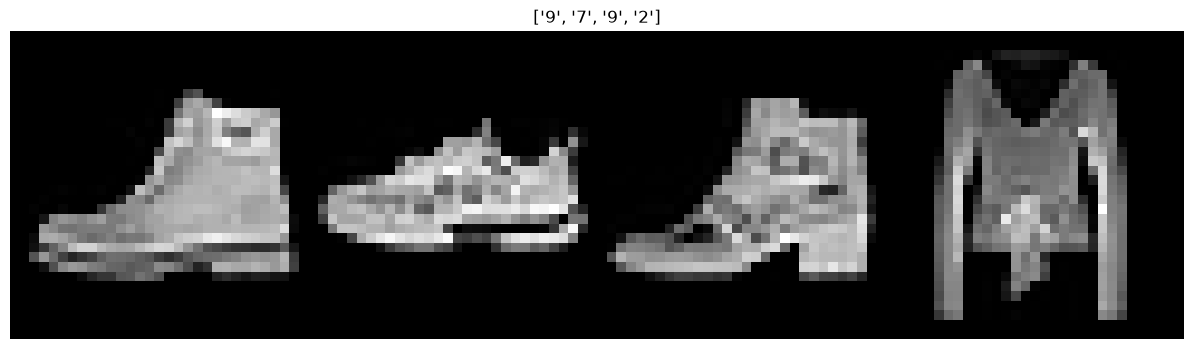

In [7]:
# 이미지 출력
images, labels = show_batch_images(trainloader)

In [8]:
# 배치 정규화가 적용되지 않은 네트워크

class NormalNet(nn.Module):
    def __init__(self):
        super(NormalNet, self).__init__()
        self.classifier = nn.Sequential(
            nn.Linear(784, 48), # (28, 28) 크기의 이미지로 입력은 784(28x28) 크기
            nn.ReLU(),
            nn.Linear(48, 24),
            nn.ReLU(),
            nn.Linear(24, 10) # FashionMNIST의 클래스는 10개
        ) # nn.Sequential을 사용하면 forward() 함수에서 계층별로 가독성 있게 코드 구현이 가능

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

In [9]:
# 배치 정규화가 포함된 네트워크

class BNNet(nn.Module):
    def __init__(self):
        super(BNNet, self).__init__()
        self.classifier = nn.Sequential(
            nn.Linear(784, 48),
            nn.BatchNorm1d(48),
            nn.ReLU(),
            nn.Linear(48, 24),
            nn.BatchNorm1d(24),
            nn.ReLU(),
            nn.Linear(24, 10)
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

In [10]:
# 배치 정규화가 적용되지 않은 모델 선언

model = NormalNet()
print(model)

NormalNet(
  (classifier): Sequential(
    (0): Linear(in_features=784, out_features=48, bias=True)
    (1): ReLU()
    (2): Linear(in_features=48, out_features=24, bias=True)
    (3): ReLU()
    (4): Linear(in_features=24, out_features=10, bias=True)
  )
)


In [11]:
# 배치 정규화가 적용된 모델 선언

model_bn = BNNet()
print(model_bn)

BNNet(
  (classifier): Sequential(
    (0): Linear(in_features=784, out_features=48, bias=True)
    (1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=48, out_features=24, bias=True)
    (4): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=24, out_features=10, bias=True)
  )
)


In [12]:
# 데이터셋 메모리로 불러오기

batch_size = 512
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)

In [13]:
# 옵티마이저, 손실 함수 지정

loss_fn = nn.CrossEntropyLoss()
opt = optim.SGD(model.parameters(), lr=0.01)
opt_bn = optim.SGD(model_bn.parameters(), lr=0.01)

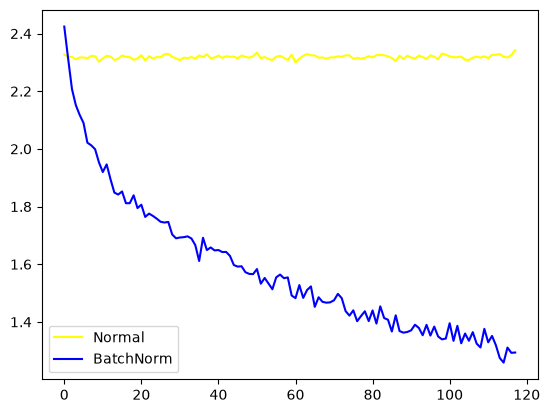

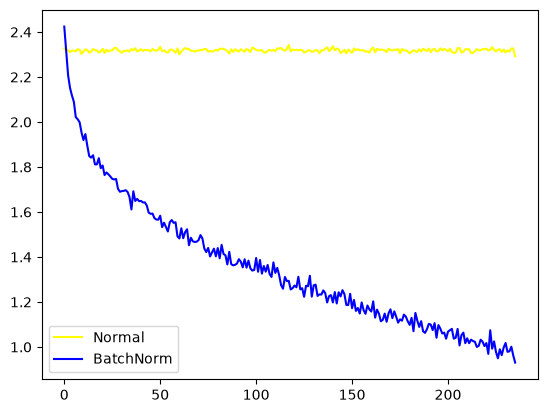

In [14]:
# 모델 학습

loss_arr = []
loss_bn_arr = []
max_epochs = 2

for epoch in range(max_epochs):
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        opt.zero_grad() # 배치 정규화가 적용되지 않은 모델의 학습
        outputs = model(inputs)
        loss = loss_fn(outputs, labels)
        loss.backward()
        opt.step

        opt_bn.zero_grad() # 배치 정규화가 적용된 모델의 학습
        outputs_bn = model_bn(inputs)
        loss_bn = loss_fn(outputs_bn, labels)
        loss_bn.backward()
        opt_bn.step()

        loss_arr.append(loss.item())
        loss_bn_arr.append(loss_bn.item())

    plt.plot(loss_arr, 'yellow', label='Normal')
    plt.plot(loss_bn_arr, 'blue', label='BatchNorm')
    plt.legend()
    plt.show()

In [15]:
# 데이터셋의 분포를 출력하기 위한 전처리

N = 50
noise = 0.3

x_train = torch.unsqueeze(torch.linspace(-1, 1, N), 1)
y_train = x_train + noise * torch.normal(torch.zeros(N, 1), torch.ones(N, 1))

x_test = torch.unsqueeze(torch.linspace(-1, 1, N), 1)
y_test = x_test + noise * torch.normal(torch.zeros(N, 1), torch.ones(N, 1))

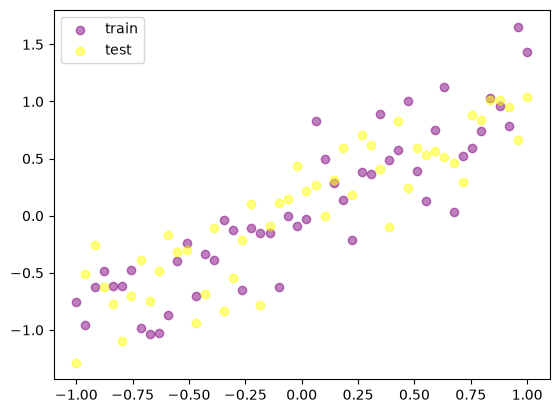

In [16]:
# 데이터 분포를 그래프로 출력

plt.scatter(x_train.data.numpy(), y_train.data.numpy(), c='purple', alpha=0.5, label='train')
plt.scatter(x_test.data.numpy(), y_test.data.numpy(), c='yellow', alpha=0.5, label='test')
plt.legend()
plt.show()

In [17]:
# 드롭아웃을 위한 모델 생성

N_h = 100
model = torch.nn.Sequential(
    torch.nn.Linear(1, N_h),
    torch.nn.ReLU(),
    torch.nn.Linear(N_h, N_h),
    torch.nn.ReLU(),
    torch.nn.Linear(N_h, 1),
) # 드롭아웃이 적용되지 않은 모델

model_dropout = torch.nn.Sequential(
    torch.nn.Linear(1, N_h),
    torch.nn.Dropout(0.2), # 드롭아웃 적용
    torch.nn.ReLU(),
    torch.nn.Linear(N_h, N_h),
    torch.nn.Dropout(0.2),
    torch.nn.ReLU(),
    torch.nn.Linear(N_h, 1)
) # 드롭아웃이 적용된 모델

In [18]:
# 옵티마이저와 손실 함수 지정

opt = torch.optim.Adam(model.parameters(), lr=0.01)
opt_dropout = torch.optim.Adam(model_dropout.parameters(), lr=0.01)
loss_fn = torch.nn.MSELoss()

C:\Users\knr\AppData\Local\Temp\ipykernel_27856\2159440338.py:31: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  plt.title('Epoch %d, Loss=%0.4f, Loss with dropout=%0.4f' % (epoch, test_loss, test_loss_dropout))


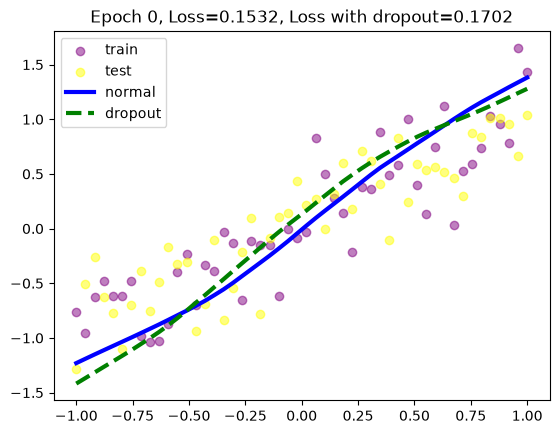

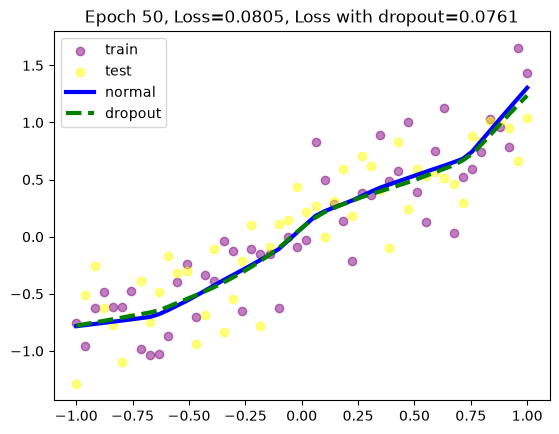

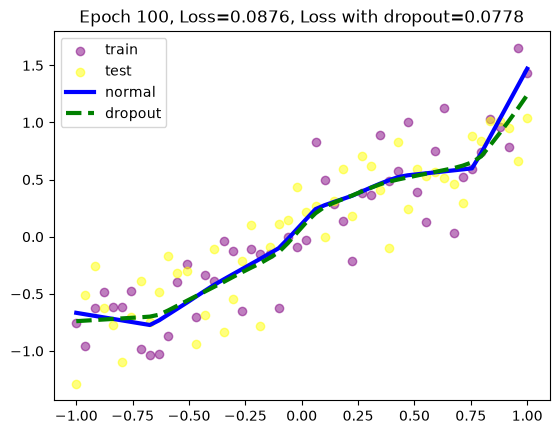

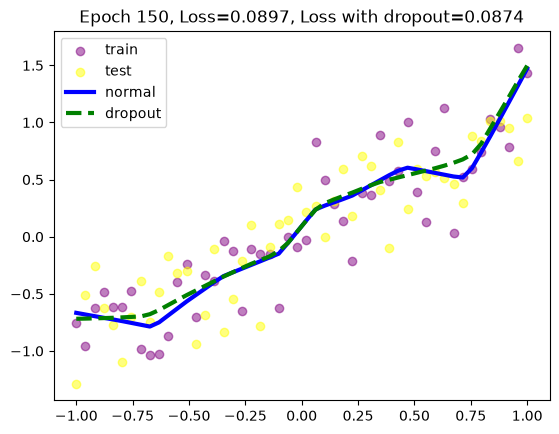

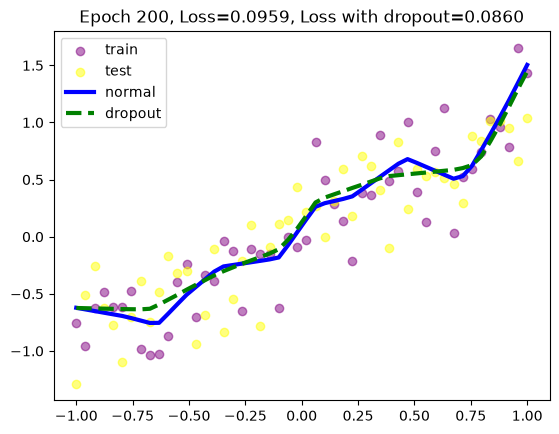

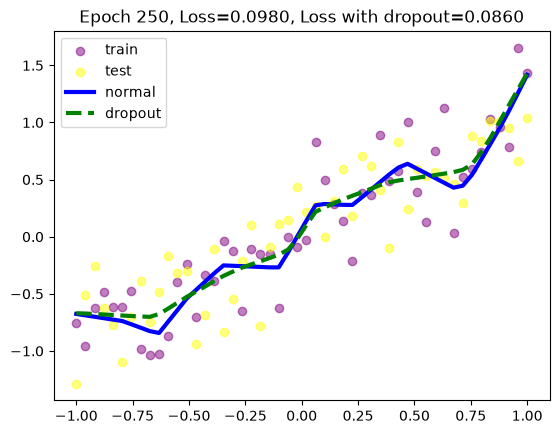

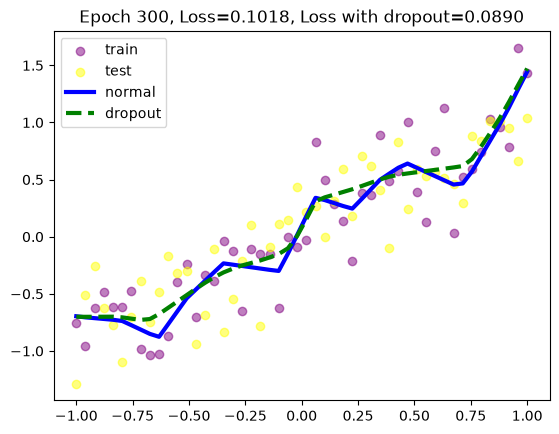

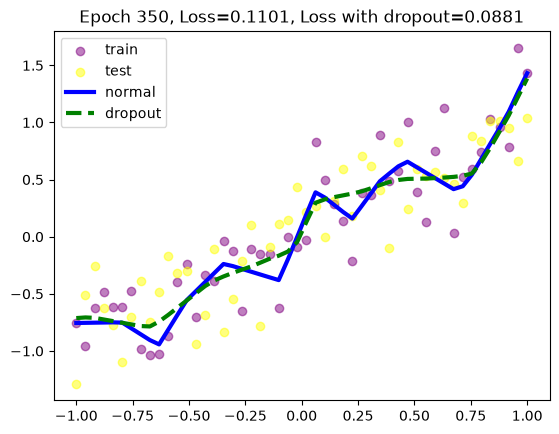

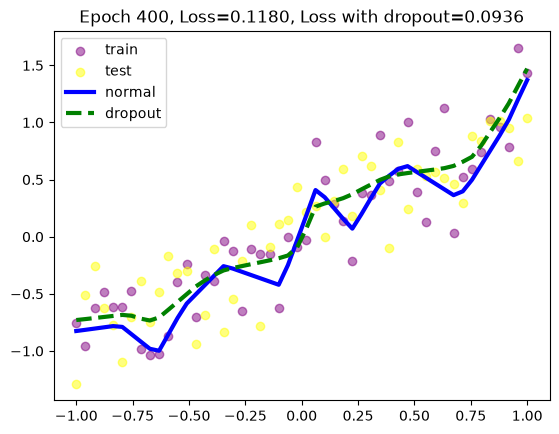

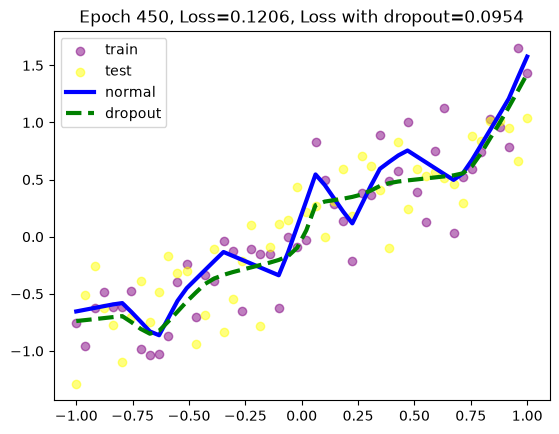

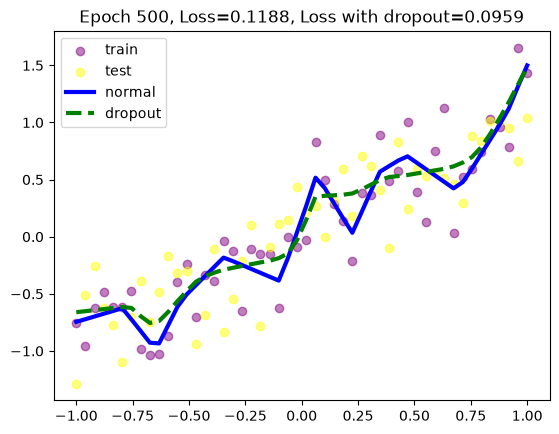

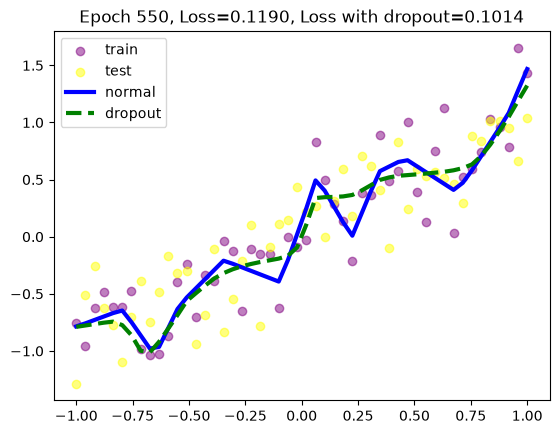

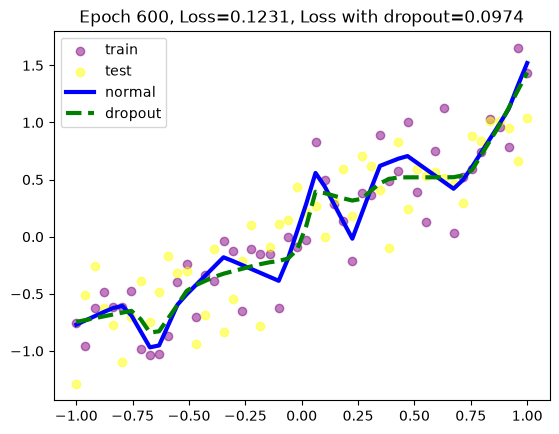

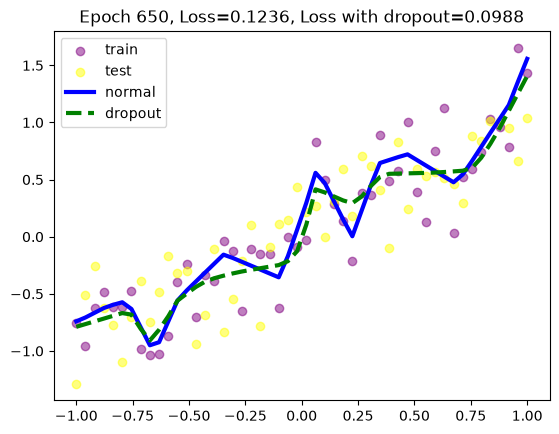

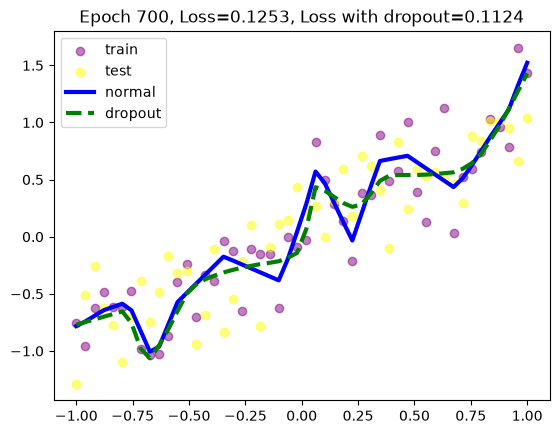

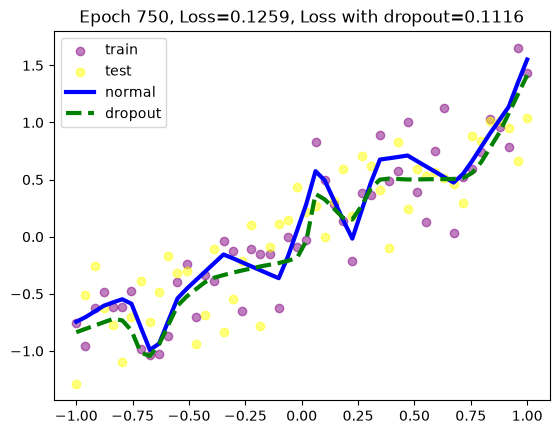

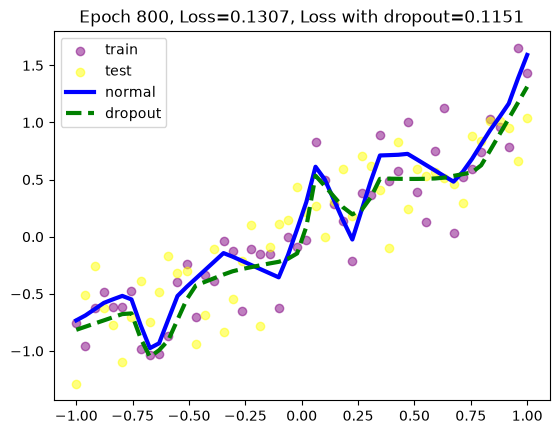

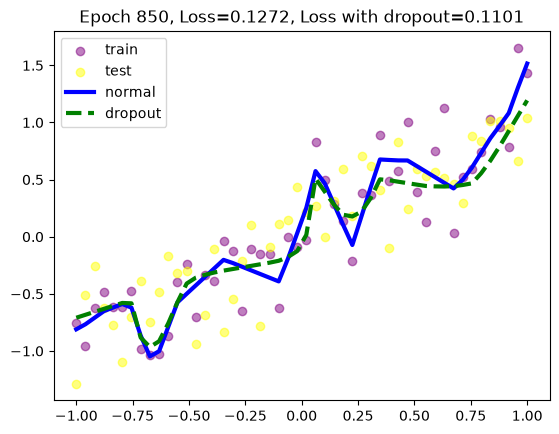

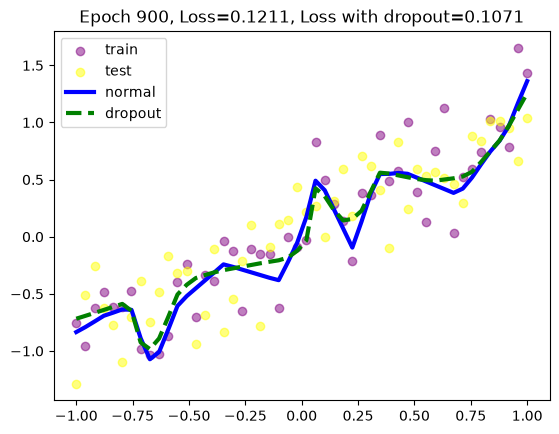

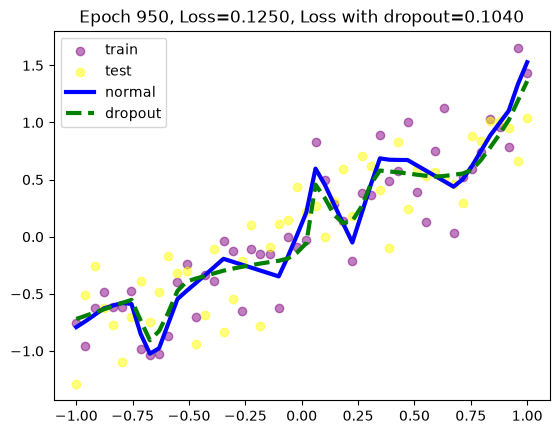

In [21]:
# 모델 학습

max_epochs = 1000
for epoch in range(max_epochs):
    pred = model(x_train) # 드롭아웃이 적용되지 않은 모델 학습
    loss = loss_fn(pred, y_train)
    opt.zero_grad()
    loss.backward()
    opt.step()

    pred_dropout = model_dropout(x_train) # 드롭아웃이 적용된 모델 학습
    loss_dropout = loss_fn(pred_dropout, y_train)
    opt_dropout.zero_grad()
    loss_dropout.backward()
    opt_dropout.step()

    if epoch % 50 == 0:
        model.eval()
        model_dropout.eval()

        test_pred = model(x_test)
        test_loss = loss_fn(test_pred, y_test)

        test_pred_dropout = model_dropout(x_test)
        test_loss_dropout = loss_fn(test_pred_dropout, y_test)

        plt.scatter(x_train.data.numpy(), y_train.data.numpy(), c='purple', alpha=0.5, label='train')
        plt.scatter(x_test.data.numpy(), y_test.data.numpy(), c='yellow', alpha=0.5, label='test')
        plt.plot(x_test.data.numpy(), test_pred.data.numpy(), 'b-', lw=3, label='normal')
        plt.plot(x_test.data.numpy(), test_pred_dropout.data.numpy(), 'g--', lw=3, label='dropout')
        plt.title('Epoch %d, Loss=%0.4f, Loss with dropout=%0.4f' % (epoch, test_loss, test_loss_dropout))
        plt.legend()
        model.train()
        model_dropout.train()
        plt.pause(0.05)

#### 8.3.3. 조기 종료를 이용한 성능 최적화

In [1]:
# 라이브러리 호출

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models # 사전 학습된 모델을 이용하고자 할 때 사용하는 라이브러리
from torchvision import transforms, datasets

import matplotlib
import matplotlib.pyplot as plt
import time

import argparse
from tqdm import tqdm
matplotlib.style.use('ggplot')
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [2]:
# 데이터셋 전처리

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.456], std=[0.229, 0.224, 0.225])
])
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [3]:
# 데이터셋 가져오기

train_dataset = datasets.ImageFolder(root=r'./data/archive/train', transform=train_transform)
train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
val_dataset = datasets.ImageFolder(root=r'./data/archive/test', transform=val_transform)
val_dataloader = torch.utils.data.DataLoader(val_dataset, batch_size=32, shuffle=False)

In [4]:
# 모델 생성

def resnet50(pretrained=True, requires_grad=False):
    model = models.resnet50(progress=True, pretrained=pretrained)
    if requires_grad == False: # 파라미터를 고정해 backward() 중에 기울기가 계산되지 않도록 함
        for param in model.parameters():
            param.requires_grad = False
    elif requires_grad == True: # 파라미터 값이 backward() 중에 기울기 계산에 반영
        for param in model.parameters():
            param.requires_grad = True
    model.fc = nn.Linear(2048, 2) # 마지막 분류를 위한 계층은 학습 진행
    return model

In [5]:
# 학습률 감소

class LRScheduler():
    def __init__(self, optimizer, patience=5, min_lr=1e-6, factor=0.5):
        self.optimizer = optimizer
        self.patience = patience
        self.min_lr = min_lr
        self.factor = factor
        self.lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer,
            mode='min',
            patience=self.patience,
            factor=self.factor,
            min_lr=self.min_lr,
            verbose=True
        )

    def __call__(self, val_loss):
        self.lr_scheduler.step(val_loss)

In [6]:
# 조기 종료

class EarlyStopping():
    def __init__(self, patience=5, verbose=False, delta=0, path='./data/checkpoint.pt'):
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None # 검증 데이터셋에 대한 오차 최적화값
        self.early_stop = False # 조기 종료
        self.val_loss_min = np.Inf # 무한대
        self.delta = delta
        self.path = path # 모델이 저장될 경로

    def __call__(self, val_loss, model): # 학습이 반복되면서 best_loss가 갱신되고, best_loss에 진전이 없으면 조기 종류 후 모델 저장
        score = -val_loss
        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model): # 검증 데이터셋에 대한 오차가 감소하면 모델을 저장
        if self.verbose:
            print(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}). Saving model ...')
        torch.save(model.state_dict(), self.path)
        self.val_loss_min = val_loss

In [7]:
# 인수 값 지정

parser = argparse.ArgumentParser() # 인수 값을 받을 수 있는 인스턴스 생성
parser.add_argument('--lr-scheduler', dest='lr_scheduler', action='store_true')
parser.add_argument('--early-stopping', dest='early_stopping', action='store_true')
args, unknown = parser.parse_known_args()
args = vars(args)

In [8]:
# 사전 훈련된 모델의 파라미터 확인

print(f"Computation device: {device}\n")
model = models.resnet50(pretrained=True).to(device)
total_parmas = sum(p.numel() for p in model.parameters()) # 총 파라미터 수
print(f"{total_parmas:,} total parameters.")
total_trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad) # 학습 가능한 파라미터 수
print(f"{total_trainable_params:,} training parameters.")

Computation device: cuda:0



f:\ESAA\.venv\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
f:\ESAA\.venv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


25,557,032 total parameters.
25,557,032 training parameters.


In [9]:
# 옵티마이저와 손실 함수 지정

lr = 0.001
epochs = 100
optimizer = optim.Adam(model.parameters(), lr=lr)
criterion = nn.CrossEntropyLoss()

In [10]:
# 오차, 정확도 및 모델의 이름에 대한 문자열

loss_plot_name = 'loss'
acc_plot_name = 'accuracy'
model_name = 'model'

In [11]:
# 오차, 정확도 및 모델의 이름에 대한 문자열

if args['lr_scheduler']:
    print('INFO: Initializing learning rate scheduler')
    lr_scheduler = LRScheduler(optimizer)
    loss_plot_name = 'lrs_loss'
    acc_plot_name = 'lrs_accuracy'
    model_name = 'lrs_model'

if args['early_stopping']:
    print('INFO: Initializing early stopping')
    early_stopping = EarlyStopping()
    loss_plot_name = 'es_loss'
    acc_plot_name = 'es_accuracy'
    model_name = 'es_model'

In [12]:
# 모델 학습 함수

def training(model, train_dataloader, train_dataset, optimizer, criterion):
    print('Training')
    model.train()
    train_running_loss = 0.0
    train_running_correct = 0
    counter = 0
    total = 0
    prog_bar = tqdm(enumerate(train_dataloader), total=int(len(train_dataset)/train_dataloader.batch_size))
    for i, data in prog_bar:
        counter += 1
        data, target = data[0].to(device), data[1].to(device)
        total += target.size(0)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, target)
        train_running_loss += loss.item()
        _, preds = torch.max(outputs.data, 1)
        train_running_correct += (preds == target).sum().item()
        loss.backward()
        optimizer.step()

    train_loss = train_running_loss / counter
    train_accuracy = 100 * train_running_correct / total
    return train_loss, train_accuracy

In [13]:
# 모델 검증 함수

def validate(model, test_dataloader, val_dataset, criterion):
    print('Validating')
    model.eval()
    val_running_loss = 0.0
    val_running_correct = 0
    counter = 0
    total = 0
    prog_bar = tqdm(enumerate(test_dataloader), total=int(len(val_dataset)/test_dataloader.batch_size))
    with torch.no_grad():
        for i, data in prog_bar:
            counter += 1
            data, target = data[0].to(device), data[1].to(device)
            total += target.size(0)
            outputs = model(data)
            loss = criterion(outputs, target)

            val_running_loss += loss.item()
            _, preds = torch.max(outputs.data, 1)
            val_running_correct += (preds == target).sum().item()

        val_loss = val_running_loss / counter
        val_accuracy = 100 * val_running_correct / total
        return val_loss, val_accuracy

In [14]:
# 모델 학습

train_loss, train_accuracy = [], [] # 훈련 데이터셋을 이용한 모델 학습 결과를 저장하기 위한 변수
val_loss, val_accuracy = [], []  # 검증 데이터셋을 이용한 모델 성능 결과를 저장하기 위한 변수

start = time.time()
for epoch in range(epochs):
    print(f"Epoch {epoch+1} of {epochs}")
    train_epoch_loss, train_epoch_accuracy = training(model, train_dataloader, train_dataset, optimizer, criterion)
    val_epoch_loss, val_epoch_accuracy = validate(model, val_dataloader, val_dataset, criterion)

    train_loss.append(train_epoch_loss)
    train_accuracy.append(train_epoch_accuracy)
    val_loss.append(val_epoch_loss)
    val_accuracy.append(val_epoch_accuracy)
    if args['lr_scheduler']:
        lr_scheduler(val_epoch_loss)
    if args['early_stopping']:
        early_stopping(val_epoch_loss, model)
        if early_stopping.early_stop:
            break
    print(f"Train Loss: {train_epoch_loss:.4f}, Train Acc: {train_epoch_accuracy:.2f}")
    print(f"Val Loss: {val_epoch_loss:.4f}, Val Acc: {val_epoch_accuracy:.2f}")
end = time.time()
print(f"Training time: {(end-start)/60:.3f} minutes")

Epoch 1 of 100
Training


16it [00:06,  2.38it/s]                        


Validating


16it [00:02,  6.45it/s]                        


Train Loss: 2.1568, Train Acc: 61.04
Val Loss: 2.5266, Val Acc: 52.20
Epoch 2 of 100
Training


16it [00:02,  5.72it/s]                        


... (391 outputs left out)

16it [00:02,  6.06it/s]                        


Validating


16it [00:02,  6.93it/s]                        

Train Loss: 0.0541, Train Acc: 98.19
Val Loss: 1.3462, Val Acc: 71.80
Training time: 9.242 minutes


Saving loss and accuracy plots...


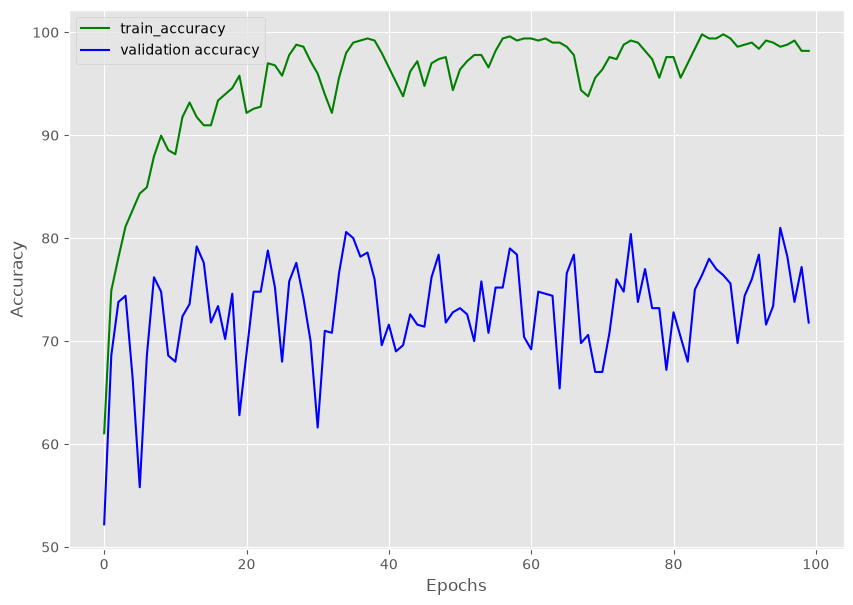

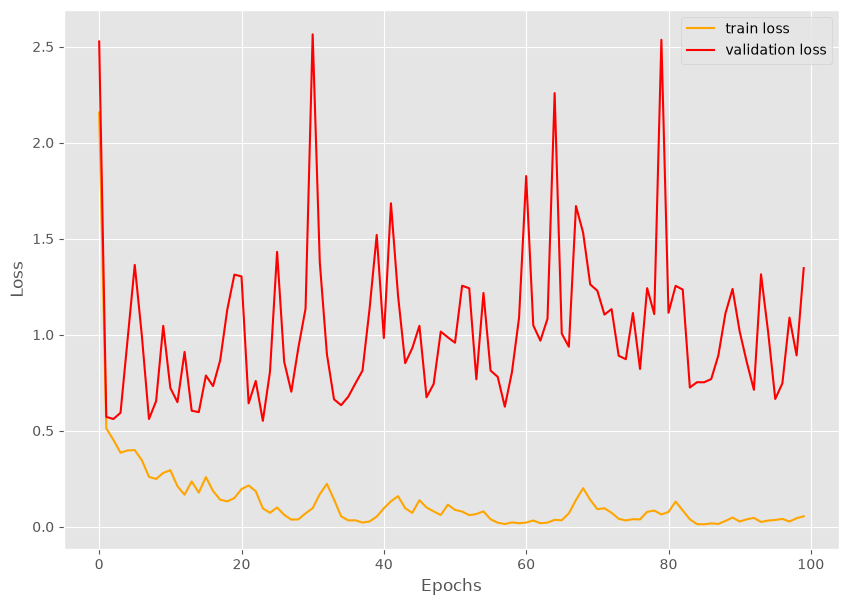

Saving model...
TRAINING COMPLETE


In [16]:
# 모델 학습 결과 출력

print('Saving loss and accuracy plots...')
plt.figure(figsize=(10, 7))
plt.plot(train_accuracy, color='green', label='train_accuracy') # 훈련 데이터셋에 대한 정확도를 그래프로 출력
plt.plot(val_accuracy, color='blue', label='validation accuracy') # 검증 데이터셋에 대한 정확도를 그래프로 출력
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig(f"./img/{acc_plot_name}.png")
plt.show()
plt.figure(figsize=(10, 7))
plt.plot(train_loss, color='orange', label='train loss') # 훈련 데이터셋에 대한 오차를 그래프로 출력
plt.plot(val_loss, color='red', label='validation loss') # 검증 데이터셋에 대한 오차를 그래프로 출력
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.savefig(f"./img/{loss_plot_name}.png")
plt.show()

print('Saving model...')
torch.save(model.state_dict(), f"./img/{model_name}.pth") # 모델 저장
print('TRAINING COMPLETE')